# 04 · Tract-table EDA

After the raw files (00-02) and the aggregation checks (03): what the assembled tract table looks like before any model: inventory, an independent check of the per-tract counts, the structural
inputs, edge-case tracts, how much the 450 sq ft filter removes, where buildings come from, how Overture compares with
USA Structures, how clean the places layer is, and how the counts move across three Overture releases.

* Runs from files already on disk; no download needed (see `docs/DATA_DOWNLOAD.md` for the full pipeline).
* Tables are saved to `eda/tables/`, figures to `eda/figures/`.
* **Audit groups are not used here.** Everything is broken down by region only, as in the disclosed Phase 1 descriptives.

In [1]:
import warnings, os, sys
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name in ("eda", "notebooks") else Path.cwd()
os.chdir(ROOT)
TAB, FIG = Path("eda/tables"), Path("eda/figures")
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
MEC = Path(yaml.safe_load(open("config/config.yaml"))["merge"]["mapequity_root"])

t = pd.read_csv("deliverables/dataset/tracts_model_table.csv", dtype={"GEOID": str, "county": str})
r = pd.read_csv("deliverables/dataset/invisible_exposure_tract_results.csv", dtype={"GEOID": str},
                usecols=["GEOID", "r2023_bldg", "r2023_bldg450", "r2026b_bldg", "r2026b_bldg450"])
b = pd.read_parquet(MEC / "eda_outputs/base_table.parquet")
d = t.merge(r, on="GEOID", how="left", validate="one_to_one")
d["region"] = pd.Categorical(d.region, REG, ordered=True)
print("tract table:", t.shape, "| release counts:", r.shape, "| MapEquityChallenge base table:", b.shape)

tract table: (9794, 112) | release counts: (9794, 5) | MapEquityChallenge base table: (9794, 84)


## 1. Inventory

In [2]:
inv = d.groupby("region", observed=True).agg(tracts=("GEOID", "size"), housing_units=("hu", "sum"), residents=("pop", "sum"),
       land_km2=("land_km2", "sum"), jobs=("jobs", "sum"), buildings=("r2026a_bldg", "sum"), buildings_450=("r2026a_bldg450", "sum"),
       places=("r2026a_poi", "sum"), usa_structures=("ref_bldg", "sum"))
inv.loc["total"] = inv.sum()
inv["tract_share"] = inv.tracts / inv.loc["total", "tracts"]
inv.to_csv(TAB / "04_01_inventory_by_region.csv")
display(inv.style.format({c: "{:,.0f}" for c in inv.columns if c != "tract_share"} | {"tract_share": "{:.1%}"}))
groups = {"identifiers": ["GEOID", "region", "county", "lat", "lon"], "ACS housing and population": [c for c in t.columns if c in ("hu", "pop", "households", "gq_pop", "vacant_share") or c.startswith(("u", "sh_"))],
          "land and density": [c for c in t.columns if "land" in c or "density" in c or c.startswith("log_")], "LODES jobs": [c for c in t.columns if c.startswith(("jobs", "jsh_"))],
          "Overture 2026-08": [c for c in t.columns if c.startswith(("r2026a_", "bsh_", "psh_", "b_", "p_"))], "USA Structures / Business Patterns": [c for c in t.columns if c.startswith("ref_")]}
print({k: len(v) for k, v in groups.items()}, "of", t.shape[1], "columns")

,tracts,housing_units,residents,land_km2,jobs,buildings,buildings_450,places,usa_structures,tract_share
region,,,,,,,,,,
maricopa-az,"1,593","2,918,893","6,823,738","218,447","2,866,671","2,908,224","2,690,193","300,044","2,445,963",16.3%
northern-ca,591,"1,030,699","2,462,332","110,681","1,026,660","1,164,723","1,089,521","116,893","969,606",6.0%
eastern-ok,"1,192","1,760,700","3,996,805","160,555","1,570,895","2,551,694","2,283,939","207,367","2,248,500",12.2%
south-central-tx,"6,003","10,686,216","26,779,333","447,549","11,663,538","11,463,800","10,582,973","1,300,281","9,714,665",61.3%
eastern-wa,415,"710,463","1,706,060","128,946","680,534","1,081,345","938,254","76,490","798,991",4.2%
total,"9,794","17,106,971","41,768,268","1,066,178","17,808,298","19,169,786","17,584,880","2,001,075","16,177,725",100.0%


{'identifiers': 5, 'ACS housing and population': 35, 'land and density': 11, 'LODES jobs': 19, 'Overture 2026-08': 32, 'USA Structures / Business Patterns': 8} of 112 columns


**Takeaway.** 9,794 tracts, 41.8 million residents, 17.1 million housing units, 19.2 million Overture buildings (17.6 million of at least 450 sq ft), 2.0 million places and 16.2 million USA Structures. South-central Texas is 61% of tracts, so pooled numbers are mostly Texas numbers; results should also be read per region. The 112 columns fall into identifiers, ACS housing and population (35), land and density (11), LODES jobs (19), Overture 2026-08 counts and sources (32), and reference counts (8).

## 2. An independent check of the per-tract counts
MapEquityChallenge built its tract table with its own code from the same challenge extracts. If both pipelines
assign Overture features to tracts correctly, their counts should agree.

In [3]:
m = d.merge(b[["GEOID", "bldg_n", "bldg_n_msft", "bldg_n_osm", "poi_n"]], on="GEOID", how="inner")
rows = []
for a, c, lab in [("r2026a_bldg", "bldg_n", "all buildings"), ("r2026a_src_msft", "bldg_n_msft", "Microsoft buildings"),
                  ("r2026a_src_osm", "bldg_n_osm", "OSM buildings"), ("r2026a_poi", "poi_n", "places")]:
    diff = m[a] - m[c]
    rows.append({"count": lab, "tracts": len(m), "identical": (diff == 0).mean(), "max_abs_diff": diff.abs().max(),
                 "total_this_repo": m[a].sum(), "total_MapEquityChallenge": m[c].sum(), "spearman": stats.spearmanr(m[a], m[c])[0]})
xc = pd.DataFrame(rows).set_index("count"); xc.to_csv(TAB / "04_02_cross_pipeline_check.csv")
display(xc.style.format({"identical": "{:.1%}", "total_this_repo": "{:,.0f}", "total_MapEquityChallenge": "{:,.0f}", "spearman": "{:.5f}"}))

,tracts,identical,max_abs_diff,total_this_repo,total_MapEquityChallenge,spearman
count,,,,,,
all buildings,9794,98.4%,7.000000,"19,169,786","19,169,788",1.00000
Microsoft buildings,9794,99.3%,2.000000,"8,273,470","8,273,471",1.00000
OSM buildings,9794,99.1%,7.000000,"9,736,234","9,736,235",1.00000
places,9794,98.9%,5.000000,"2,001,075","2,001,201",1.00000


**Takeaway.** Two independently written pipelines give essentially the same counts: identical in 98.4% of tracts for all buildings, 99.3% for Microsoft buildings and 98.9% for places, with a largest difference of 7 buildings and totals that differ by 2 buildings (and 126 places, 0.006%). Assigning 19 million footprints to tracts is therefore not a source of error in this project.

## 3. Structural inputs (the only model inputs)

,mean,1%,50%,99%,max,skew,skew_log1p,zeros,missing
hu,1746.679,41.440,1645.000,4278.260,13827.000,1.937,-6.059,82,0
pop,4264.679,802.720,3962.000,11663.820,44364.000,2.857,-6.301,51,0
households,1581.615,29.720,1477.000,3991.280,12756.000,1.959,-5.750,85,0
land_km2,108.860,0.390,3.966,2134.940,8892.508,8.541,1.336,2,0
hu_density,572.404,0.165,421.510,3766.512,10193.647,3.999,-1.041,80,2
pop_density,1324.072,0.673,1049.196,6752.022,26251.329,3.396,-1.210,49,2
jobs,1818.287,27.000,808.000,17092.630,81541.000,8.489,-0.277,16,0
vacant_share,0.098,0.000,0.078,0.413,1.000,2.346,1.735,501,82
sh_u1_det,0.661,0.006,0.720,1.000,1.000,-0.851,-1.181,82,82
sh_u_mobile,0.071,0.000,0.010,0.539,1.000,2.408,2.024,4061,82


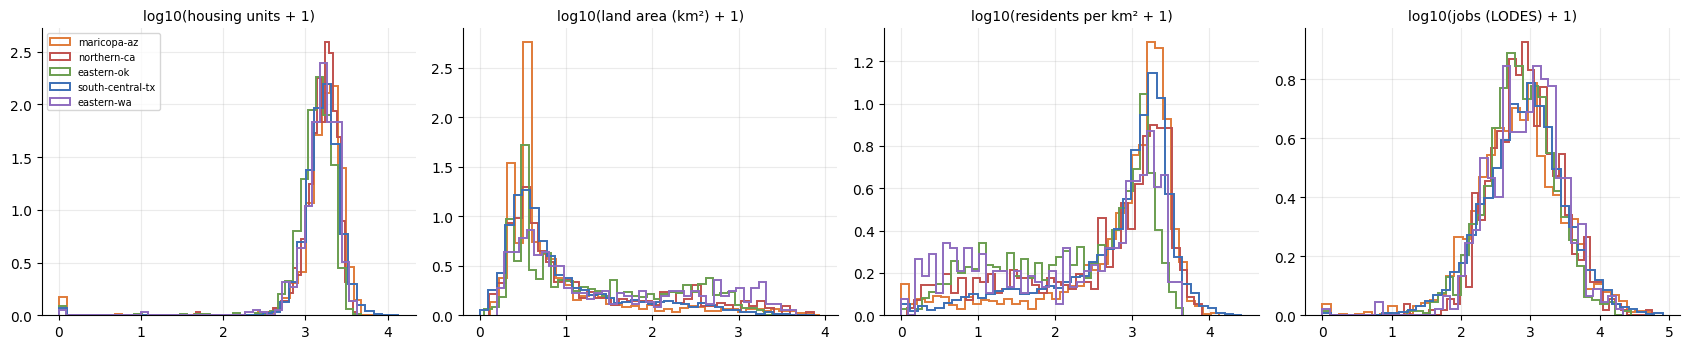

top 1% of tracts by area hold 31.3% of all land


In [4]:
S = ["hu", "pop", "households", "land_km2", "hu_density", "pop_density", "jobs", "vacant_share", "sh_u1_det", "sh_u_mobile"]
desc = d[S].describe(percentiles=[.01, .5, .99]).T
desc["skew"] = d[S].skew(); desc["skew_log1p"] = np.log1p(d[S].clip(lower=0)).skew(); desc["zeros"] = (d[S] == 0).sum(); desc["missing"] = d[S].isna().sum()
desc.to_csv(TAB / "04_03_structural_inputs.csv")
display(desc[["mean", "1%", "50%", "99%", "max", "skew", "skew_log1p", "zeros", "missing"]])
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, c, lab in zip(ax, ["hu", "land_km2", "pop_density", "jobs"], ["housing units", "land area (km²)", "residents per km²", "jobs (LODES)"]):
    for reg in REG:
        v = np.log10(d.loc[d.region == reg, c].clip(lower=0) + 1)
        a.hist(v, bins=40, histtype="step", lw=1.4, color=COL[reg], label=reg, density=True)
    a.set_title(f"log10({lab} + 1)", fontsize=10)
ax[0].legend(fontsize=7); save("04_03_structural_distributions")
top = d.land_km2.sort_values(ascending=False)
print(f"top 1% of tracts by area hold {top.head(int(len(d) * .01)).sum() / top.sum():.1%} of all land")

**Takeaway.** Every count input is right-skewed (land area skew 8.5, jobs 8.5) and nearly symmetric after a log transform, which is why the model works on log counts. Land area is extreme: the top 1% of tracts hold 31% of all land. Zeros are rare (82 tracts with no housing units, 51 with no residents) but they exist, so any ratio to housing or population needs a guard. Mobile-home share is zero in 4,061 tracts and up to 100% in others.

### Collinearity among the structural inputs

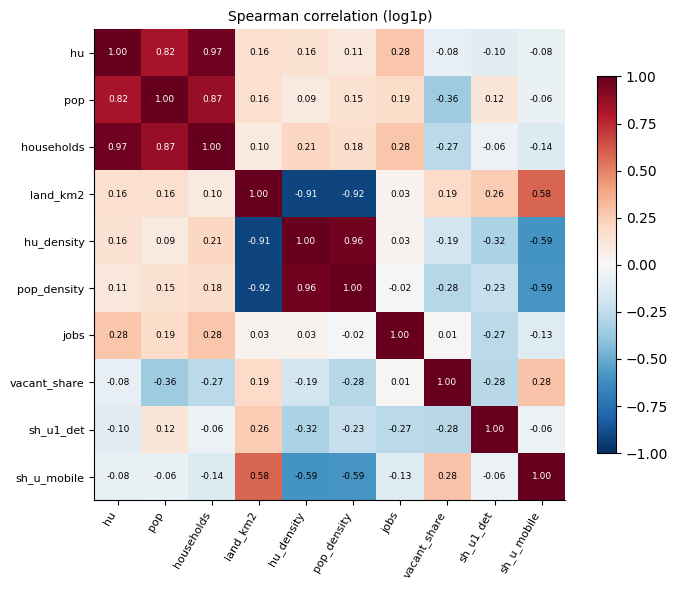

In [5]:
cm = np.log1p(d[S].clip(lower=0)).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6)); im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(S))); ax.set_xticklabels(S, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(S))); ax.set_yticklabels(S, fontsize=8)
for i in range(len(S)):
    for j in range(len(S)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="w" if abs(cm.iloc[i, j]) > .6 else "k")
plt.colorbar(im, ax=ax, shrink=.8); plt.title("Spearman correlation (log1p)", fontsize=10); save("04_03b_collinearity")

**Takeaway.** Housing units, households and population move together (Spearman 0.82-0.97), and land area is almost the mirror of housing and population density (-0.91, -0.92). Mobile-home share tracks low density (0.58 with land area). Tree models such as LightGBM handle this, but feature importances among these columns should not be over-read. Jobs are nearly independent of housing (0.28), which is why LODES adds information for places.

## 4. Edge-case tracts

In [6]:
w = b.set_index("GEOID").reindex(d.GEOID)
edge = pd.DataFrame({
    "zero land area": d.land_km2.eq(0).values, "more than 50% water": (w.water_share > .5).values,
    "zero housing units": d.hu.eq(0).values, "zero population": d["pop"].eq(0).values,
    "under 50 housing units": (d.hu < 50).values, "no Overture building": d.r2026a_bldg.eq(0).values,
    "no Overture place": d.r2026a_poi.eq(0).values, "no USA Structures count": d.ref_bldg.isna().values,
    "USA Structures under 10": (d.ref_bldg < 10).values}, index=d.index)
et = edge.groupby(d.region.values, observed=True).sum().T.reindex(columns=REG); et["total"] = et.sum(axis=1); et.to_csv(TAB / "04_04_edge_case_tracts.csv")
display(et)
print("tracts with zero land area:"); display(d.loc[d.land_km2.eq(0), ["GEOID", "region", "hu", "pop", "r2026a_bldg", "r2026a_poi", "ref_bldg"]])

,maricopa-az,northern-ca,eastern-ok,south-central-tx,eastern-wa,total
zero land area,0,0,0,2,0,2
more than 50% water,0,2,1,40,0,43
zero housing units,27,0,10,43,2,82
zero population,17,0,3,29,2,51
under 50 housing units,33,1,13,52,3,102
no Overture building,0,0,0,2,0,2
no Overture place,0,0,0,2,0,2
no USA Structures count,0,0,0,1,0,1
USA Structures under 10,2,0,2,1,0,5


tracts with zero land area:


,GEOID,region,hu,pop,r2026a_bldg,r2026a_poi,ref_bldg
8129,48039990000,south-central-tx,0,0,0.0,0.0,2.0
8141,48057990000,south-central-tx,0,0,0.0,0.0,NaN


**Takeaway.** A handful of tracts need care: 2 Texas tracts have zero land area and no Overture features at all (100% water), 43 are more than half water (40 in Texas), 82 have no housing units and 102 fewer than 50. Only one tract lacks a USA Structures count and five have fewer than 10 structures, which is why the absorption analysis drops reference counts under 10.

## 5. How much does the 450 sq ft filter remove?

,buildings,buildings_450,median_tract_share_kept,median_buildings_per_hu,share_removed
region,,,,,
maricopa-az,"2,908,224","2,690,193",96.8%,0.98,7.5%
northern-ca,"1,164,723","1,089,521",95.5%,1.05,6.5%
eastern-ok,"2,551,694","2,283,939",92.9%,1.34,10.5%
south-central-tx,"11,463,800","10,582,973",96.3%,1.04,7.7%
eastern-wa,"1,081,345","938,254",88.3%,1.41,13.2%


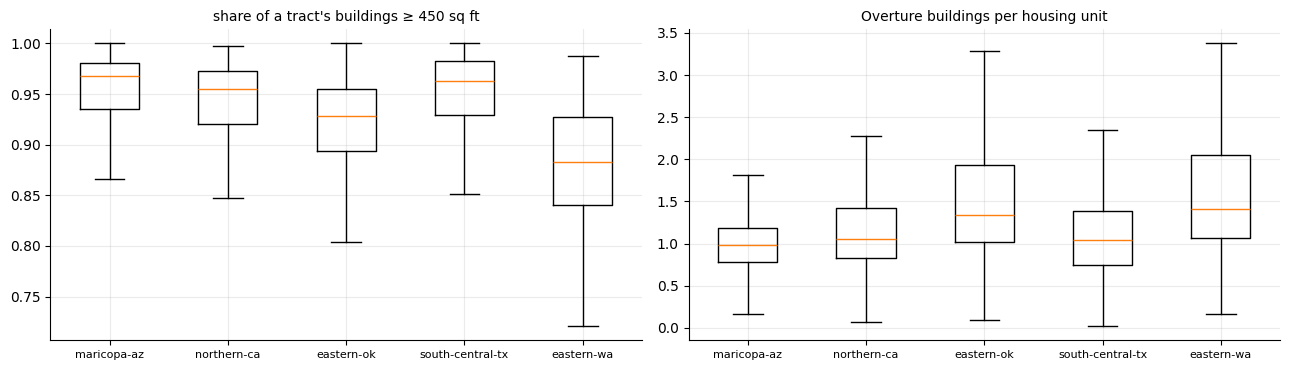

In [7]:
d["share_450"] = d.r2026a_bldg450 / d.r2026a_bldg.replace(0, np.nan)
d["bldg_per_hu"] = d.r2026a_bldg / d.hu.replace(0, np.nan)
f = d.groupby("region", observed=True).agg(buildings=("r2026a_bldg", "sum"), buildings_450=("r2026a_bldg450", "sum"),
     median_tract_share_kept=("share_450", "median"), median_buildings_per_hu=("bldg_per_hu", "median"))
f["share_removed"] = 1 - f.buildings_450 / f.buildings; f.to_csv(TAB / "04_05_size_filter.csv")
display(f.style.format({"buildings": "{:,.0f}", "buildings_450": "{:,.0f}", "median_tract_share_kept": "{:.1%}", "share_removed": "{:.1%}", "median_buildings_per_hu": "{:.2f}"}))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].boxplot([d.loc[d.region == g, "share_450"].dropna() for g in REG], labels=REG, showfliers=False); ax[0].set_title("share of a tract's buildings ≥ 450 sq ft", fontsize=10)
ax[1].boxplot([d.loc[d.region == g, "bldg_per_hu"].dropna() for g in REG], labels=REG, showfliers=False); ax[1].set_title("Overture buildings per housing unit", fontsize=10)
for a in ax: a.tick_params(axis="x", labelsize=8)
save("04_05_size_filter")

**Takeaway.** The 450 sq ft filter removes 7.5-13% of buildings: least in Maricopa and northern CA, most in eastern OK (10.5%) and eastern WA (13.2%), where sheds and outbuildings are common. It is needed because USA Structures only counts structures above that size. Overture has about one building per housing unit in Maricopa, CA and Texas, and 1.3-1.4 in eastern OK and eastern WA.

## 6. Where do the buildings come from?

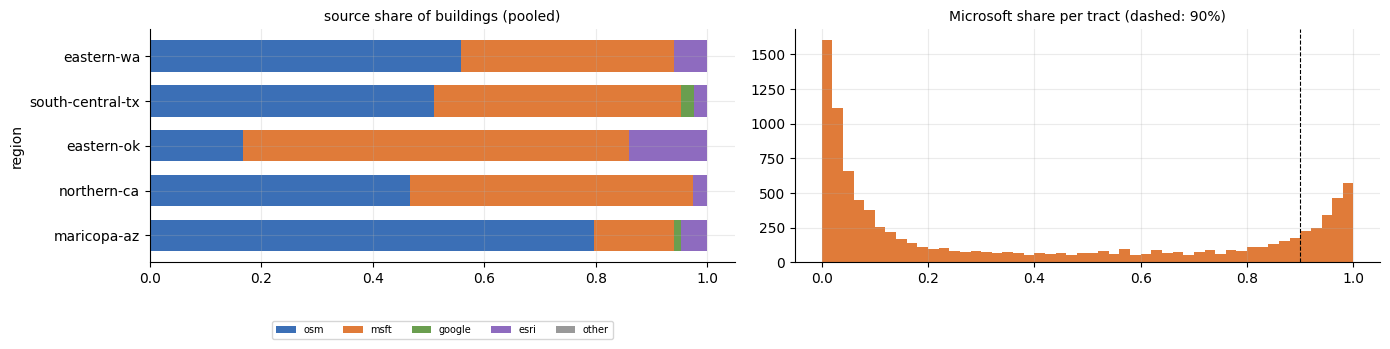

,osm,msft,google,esri,other
region,,,,,
maricopa-az,79.7%,14.3%,1.3%,4.7%,0.0%
northern-ca,46.6%,50.8%,0.0%,2.6%,0.0%
eastern-ok,16.7%,69.4%,0.0%,14.0%,0.0%
south-central-tx,51.0%,44.3%,2.2%,2.4%,0.0%
eastern-wa,55.9%,38.1%,0.0%,6.0%,0.0%


Microsoft-dominant tracts (>= 90%): 1,854 (18.9%); single-source tracts: 5,245
places by source (pooled): meta 60.5%, msft 16.4%, fsq 7.2%


In [8]:
src = ["r2026a_src_osm", "r2026a_src_msft", "r2026a_src_google", "r2026a_src_esri", "r2026a_src_other"]
mix = d.groupby("region", observed=True)[src].sum(); mix = mix.div(mix.sum(axis=1), axis=0); mix.columns = [c.split("_")[-1] for c in src]; mix.to_csv(TAB / "04_06_building_sources.csv")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
mix.plot.barh(stacked=True, ax=ax[0], color=["#3b6fb6", "#e07b39", "#6a9e4f", "#8e6bbf", "#999999"], width=.7); ax[0].set_title("source share of buildings (pooled)", fontsize=10); ax[0].legend(fontsize=7, ncol=5, loc="lower center", bbox_to_anchor=(.5, -.35))
ax[1].hist(d.bsh_msft, bins=50, color="#e07b39"); ax[1].axvline(.9, color="k", ls="--", lw=.8); ax[1].set_title("Microsoft share per tract (dashed: 90%)", fontsize=10)
save("04_06_building_sources")
display(mix.style.format("{:.1%}"))
print(f"Microsoft-dominant tracts (>= 90%): {(d.bsh_msft >= .9).sum():,} ({(d.bsh_msft >= .9).mean():.1%}); single-source tracts: {int(d.b_single_source.sum()):,}")
print(f"places by source (pooled): " + ", ".join(f"{c[4:]} {d[c].mul(d.r2026a_poi).sum() / d.r2026a_poi.sum():.1%}" for c in ["psh_meta", "psh_msft", "psh_fsq"]))

**Takeaway.** Building provenance differs sharply by region: OpenStreetMap supplies 80% of Maricopa's buildings, but Microsoft's machine-learned footprints supply 69% in eastern OK and about half in northern CA. 1,854 tracts (18.9%) get at least 90% of their buildings from Microsoft. More than half of tracts (5,245) are effectively single-source. Places come mainly from Meta (60.5%).

## 7. Overture against USA Structures (reference-based descriptive, by region)
Both count buildings over 450 sq ft. A tract is a *reference gap* if Overture has fewer than 80% of the USA Structures count.

,tracts,median_ratio,p10,p90,gap_share,over_125
region,,,,,,
maricopa-az,"1,593",1.029,0.96,1.29,1.0%,12.6%
northern-ca,591,1.086,1.00,1.33,1.4%,15.4%
eastern-ok,"1,192",1.021,0.92,1.19,3.4%,6.1%
south-central-tx,"6,002",1.046,0.95,1.27,2.0%,11.1%
eastern-wa,415,1.142,1.04,1.31,0.0%,17.8%
all,"9,793",1.047,0.95,1.27,1.9%,11.3%


log-scale Pearson r = 0.975


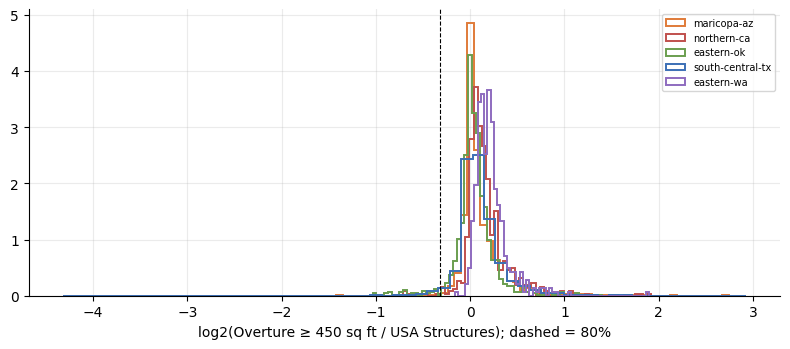

In [9]:
s = d[d.ref_bldg.notna()].copy(); s["ratio"] = s.r2026a_bldg450 / s.ref_bldg
rg = s.groupby("region", observed=True).agg(tracts=("ratio", "size"), median_ratio=("ratio", "median"), p10=("ratio", lambda x: x.quantile(.1)),
      p90=("ratio", lambda x: x.quantile(.9)), gap_share=("ratio", lambda x: (x < .8).mean()), over_125=("ratio", lambda x: (x > 1.25).mean()))
rg.loc["all"] = [len(s), s.ratio.median(), s.ratio.quantile(.1), s.ratio.quantile(.9), (s.ratio < .8).mean(), (s.ratio > 1.25).mean()]
rg.to_csv(TAB / "04_07_overture_vs_usa_structures.csv")
display(rg.style.format({"tracts": "{:,.0f}", "median_ratio": "{:.3f}", "p10": "{:.2f}", "p90": "{:.2f}", "gap_share": "{:.1%}", "over_125": "{:.1%}"}))
print(f"log-scale Pearson r = {np.corrcoef(np.log1p(s.r2026a_bldg450), np.log1p(s.ref_bldg))[0, 1]:.3f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
for g in REG:
    ax.hist(np.log2(s.loc[s.region == g, "ratio"].clip(.05, 20)), bins=60, histtype="step", lw=1.4, color=COL[g], label=g, density=True)
ax.axvline(np.log2(.8), color="k", ls="--", lw=.8); ax.set_xlabel("log2(Overture ≥ 450 sq ft / USA Structures); dashed = 80%"); ax.legend(fontsize=7); save("04_07_overture_vs_usa_structures")

**Takeaway.** Overture and USA Structures agree closely (log-scale r = 0.975; median ratio 1.047). Overture is usually slightly above the reference (11% of tracts above 125%), and only 1.9% of tracts fall below 80%. Gaps are most common in eastern OK (3.4%) and absent in eastern WA. This is the Phase 1 descriptive disclosed in the pre-registration, shown here by region only.

## 8. How clean is the places layer?

In [10]:
pq = b[["GEOID", "region", "poi_n", "poi_n_closed", "poi_n_nocat", "poi_n_conf05", "poi_n_fire", "poi_n_fire_alt", "poi_n_ems", "poi_n_ems_alt", "poi_n_fire_altonly"]].copy()
g = pq.groupby("region")[pq.columns[2:]].sum().reindex(REG)
out = pd.DataFrame({"places": g.poi_n, "permanently_closed": g.poi_n_closed / g.poi_n, "no_primary_category": g.poi_n_nocat / g.poi_n,
                    "confidence_under_0.5": 1 - g.poi_n_conf05 / g.poi_n,
                    "fire: alternate-only adds": g.poi_n_fire_altonly / g.poi_n_fire, "EMS: alternate / primary": g.poi_n_ems_alt / g.poi_n_ems,
                    "tracts with a fire POI": pq.assign(x=pq.poi_n_fire > 0).groupby("region").x.mean().reindex(REG),
                    "tracts with an EMS POI": pq.assign(x=pq.poi_n_ems > 0).groupby("region").x.mean().reindex(REG)})
out.to_csv(TAB / "04_08_poi_quality.csv")
display(out.style.format({"places": "{:,.0f}"} | {c: "{:.1%}" for c in out.columns if c not in ("places", "EMS: alternate / primary")} | {"EMS: alternate / primary": "{:.1f}x"}))

,places,permanently_closed,no_primary_category,confidence_under_0.5,fire: alternate-only adds,EMS: alternate / primary,tracts with a fire POI,tracts with an EMS POI
region,,,,,,,,
maricopa-az,"300,049",2.7%,4.9%,10.0%,24.0%,3.2x,23.4%,4.1%
northern-ca,"116,901",2.5%,4.1%,10.3%,31.1%,3.7x,35.9%,5.1%
eastern-ok,"207,371",2.0%,4.1%,9.9%,30.2%,2.8x,36.2%,8.6%
south-central-tx,"1,300,388",2.2%,6.1%,12.4%,20.0%,2.2x,28.8%,8.0%
eastern-wa,"76,492",2.0%,4.0%,10.5%,36.9%,2.6x,32.8%,9.2%


**Takeaway.** About 2-3% of places are marked permanently closed but still counted, 4-6% have no primary category and 10-12% have confidence below 0.5. Emergency facilities are often hidden in the alternate categories: places that list a fire department only as an alternate would add 20-37% to the primary count, and EMS appears 2.2-3.7 times as often in alternates as in the primary category. Only 23-36% of tracts have a fire POI and 4-9% an EMS POI. These are reasons, besides the area allocation of Business Patterns, why POI validation is noisier than building validation.

## 9. Counts across three Overture releases

,r2023_bldg450,r2026a_bldg450,r2026b_bldg450,change_2023_to_2026_08,change_2026_08_to_2026_10
region,,,,,
maricopa-az,"2,542,286","2,690,193","2,688,839",+5.8%,-0.1%
northern-ca,"1,001,597","1,089,521","1,095,728",+8.8%,+0.6%
eastern-ok,"2,115,123","2,283,939","2,286,684",+8.0%,+0.1%
south-central-tx,"9,708,484","10,582,973","10,452,884",+9.0%,-1.2%
eastern-wa,"867,727","938,254","934,995",+8.1%,-0.3%
all,"16,235,217","17,584,880","17,459,130",+8.3%,-0.7%


tracts losing > 20% between 2026-08 and 2026-10: 186 (48029 is the main county)


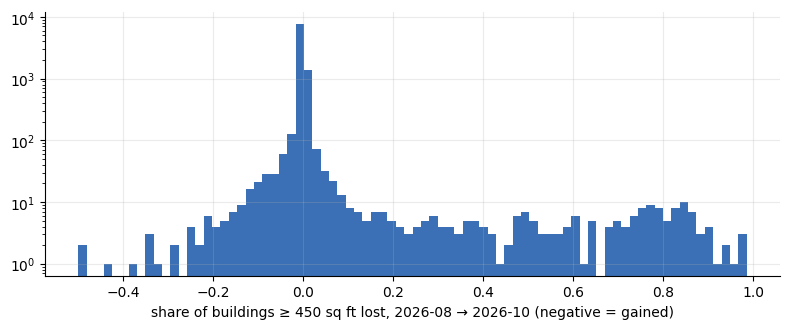

In [11]:
rel = d.groupby("region", observed=True)[["r2023_bldg450", "r2026a_bldg450", "r2026b_bldg450"]].sum()
rel.loc["all"] = rel.sum()
rel["change_2023_to_2026_08"] = rel.r2026a_bldg450 / rel.r2023_bldg450 - 1; rel["change_2026_08_to_2026_10"] = rel.r2026b_bldg450 / rel.r2026a_bldg450 - 1; rel.to_csv(TAB / "04_09_releases.csv")
display(rel.style.format({c: "{:,.0f}" for c in rel.columns[:3]} | {c: "{:+.1%}" for c in rel.columns[3:]}))
d["loss"] = (d.r2026a_bldg450 - d.r2026b_bldg450) / d.r2026a_bldg450.clip(lower=1)
print(f"tracts losing > 20% between 2026-08 and 2026-10: {(d.loss > .2).sum()} ({(d.loss > .2).groupby(d.county).sum().sort_values().index[-1]} is the main county)")
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.hist(d.loss.clip(-.5, 1), bins=80, color="#3b6fb6"); ax.set_yscale("log")
ax.set_xlabel("share of buildings ≥ 450 sq ft lost, 2026-08 → 2026-10 (negative = gained)"); save("04_09_release_change")

**Takeaway.** Between 2023-07 and 2026-08 every region gained 6-9% of buildings of at least 450 sq ft. Between 2026-08 and 2026-10 the total fell by 0.7%, almost entirely in south-central Texas (-1.2%): 186 tracts lost more than 20%, mostly in Bexar County (48029). This is the release regression analysed in the paper.

## 10. Summary

The data are well suited to the analysis: counts are verified by an independent pipeline, the reference agrees closely with the map, and only a few dozen edge-case tracts need special handling. Three features of the data shape the method and its limits: (1) strong skew and collinearity in the structural inputs (log counts, tree models); (2) large regional differences in building provenance, so a single pooled model must be calibrated per region; and (3) a places layer with closed, uncategorised and alternate-only records, which makes POI validation approximate. The 2026-10 drop in Texas is visible even in raw regional totals.